# Experiment 2: Simple Linear Regression

**Objective:**
1. Clean data by removing duplicates and imputing missing values.
2. Train a Simple Linear Regression model to predict `Final_Score` from `Study_Hours`.
3. Evaluate model performance using Mean Squared Error (MSE) and $R^2$ Score.
4. Plot the regression line over the data points.

### Step 1: Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

### Step 2: Load and Clean Dataset

In [2]:
# Load dataset
df = pd.read_csv('./data_2.csv')
print(f"Initial shape: {df.shape}")

# Remove duplicate records
df = df.drop_duplicates()

# Impute missing values with column means
df = df.fillna(df.mean(numeric_only=True))

print(f"Cleaned shape: {df.shape}")
print(df.head())

Initial shape: (200, 6)
Cleaned shape: (192, 6)
  Student_ID  Study_Hours  ...  Internal_Marks  Final_Score
0       S001     5.300000  ...            61.4         37.3
1       S002     2.900000  ...            73.3         68.7
2       S003     6.200000  ...            55.3         65.5
3       S004     6.500000  ...            62.9         65.2
4       S005     4.870899  ...            40.1         56.1

[5 rows x 6 columns]


### Step 3: Select Feature (X) and Target (y), and Split Data

In [3]:
# X is a 2D DataFrame (features), y is a 1D Series (target)
X = df[['Study_Hours']]
y = df['Final_Score']

# Split: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples : {len(X_test)}")

Training samples: 153
Testing samples : 39


### Step 4: Train Linear Regression Model

In [4]:
# Initialize and fit Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Slope (m) and Intercept (c)
slope = model.coef_[0]
intercept = model.intercept_

print(f"Slope (m)    : {slope:.4f}")
print(f"Intercept (c): {intercept:.4f}")
print(f"Equation     : Final_Score = ({slope:.2f} * Study_Hours) + {intercept:.2f}")

Slope (m)    : -0.3062
Intercept (c): 56.4937
Equation     : Final_Score = (-0.31 * Study_Hours) + 56.49


### Step 5: Predict and Evaluate on Test Set

In [5]:
# Predict test set values
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"R-squared Score (R2)     : {r2:.4f}")

Mean Squared Error (MSE) : 90.57
R-squared Score (R2)     : -0.0080


### Step 6: Visualize Regression Line

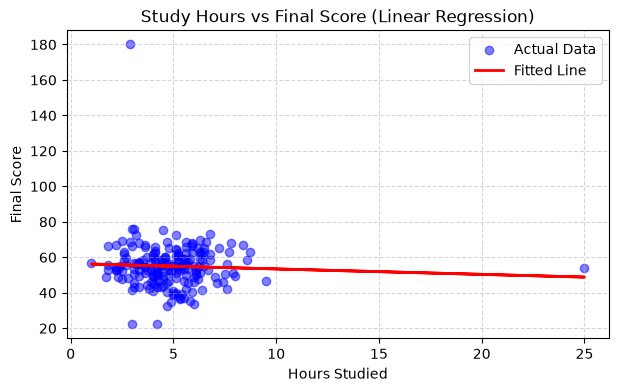

In [6]:
# Scatter plot of actual values + fitted regression line
plt.figure(figsize=(7, 4))
plt.scatter(X, y, color='blue', alpha=0.5, label='Actual Data')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Fitted Line')
plt.xlabel("Hours Studied")
plt.ylabel("Final Score")
plt.title("Study Hours vs Final Score (Linear Regression)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()